# HS4002 Week 4

## Task for the day

We'll investigate three relationships:
1. Age and annual income
2. Income and cultural omnivorousness
3. Race and highest education level attained

For each question: (a) visualize, then (b) compute a bivariate statistic.

In [1]:
# !pip install pandas numpy scipy plotnine

import pandas as pd
import numpy as np
import plotnine as p9
import warnings
warnings.filterwarnings('ignore')
from scipy import stats

## Data Preparation

In [3]:
raw_df = pd.read_csv("gss2022_mini.csv")

chosen_variables = [
	"id", "age", "yrlvmus", "yrartxbt", "yrmovie", "yrcreat",
	"income16", "prestg10", "degree", "race"
]
df = raw_df[chosen_variables].dropna().copy()

income_map = {
	1: 500,    2: 2000,   3: 3500,   4: 4500,   5: 5500,   6: 6500,
	7: 7500,   8: 9000,   9: 11250,  10: 13750, 11: 16250, 12: 18750,
	13: 21250, 14: 23750, 15: 27500, 16: 32500, 17: 37500, 18: 45000,
	19: 55000, 20: 67500, 21: 82500, 22: 100000, 23: 120000, 24: 140000,
	25: 160000, 26: 250000
}
df['income_cont'] = df['income16'].map(income_map)

# first asks if value is equal to 1 or not, then marks 1 as true and other values as false
# as.type(int) then turns these true/false values into 1/0

df['binary_lvmus']  = (df['yrlvmus']  == 1).astype(int)
df['binary_artxbt'] = (df['yrartxbt'] == 1).astype(int)
df['binary_movie']  = (df['yrmovie']  == 1).astype(int)
df['binary_creat']  = (df['yrcreat']  == 1).astype(int)
df['omni'] = df[['binary_lvmus','binary_artxbt','binary_movie','binary_creat']].sum(axis=1) # axis=1 tells python to add across the rows, not down them

# Investigating the relation between age and annual income

## Calculating covariance

In [4]:
# np.cov returns a 2x2 matrix. [0,1] tells python which part of the matrix to draw the covariance from
cov_val = np.cov(df['age'], df['income_cont'])[0, 1] # calculate covariance between age and income
print(f'Covariance(age, income): {cov_val:.2f}') # interpretation: since covariance is positive, age and income tend to increase together

np.cov(df['age'], df['income_cont'])
# explaining the values in the matrix:
# top left is the variance of the age, bottom right is the variance of the income
# the other 2 values are the covariance of age and income!

Covariance(age, income): 6961.46


array([[3.01191425e+02, 6.96146150e+03],
       [6.96146150e+03, 5.17655627e+09]])

## Data Visualisation


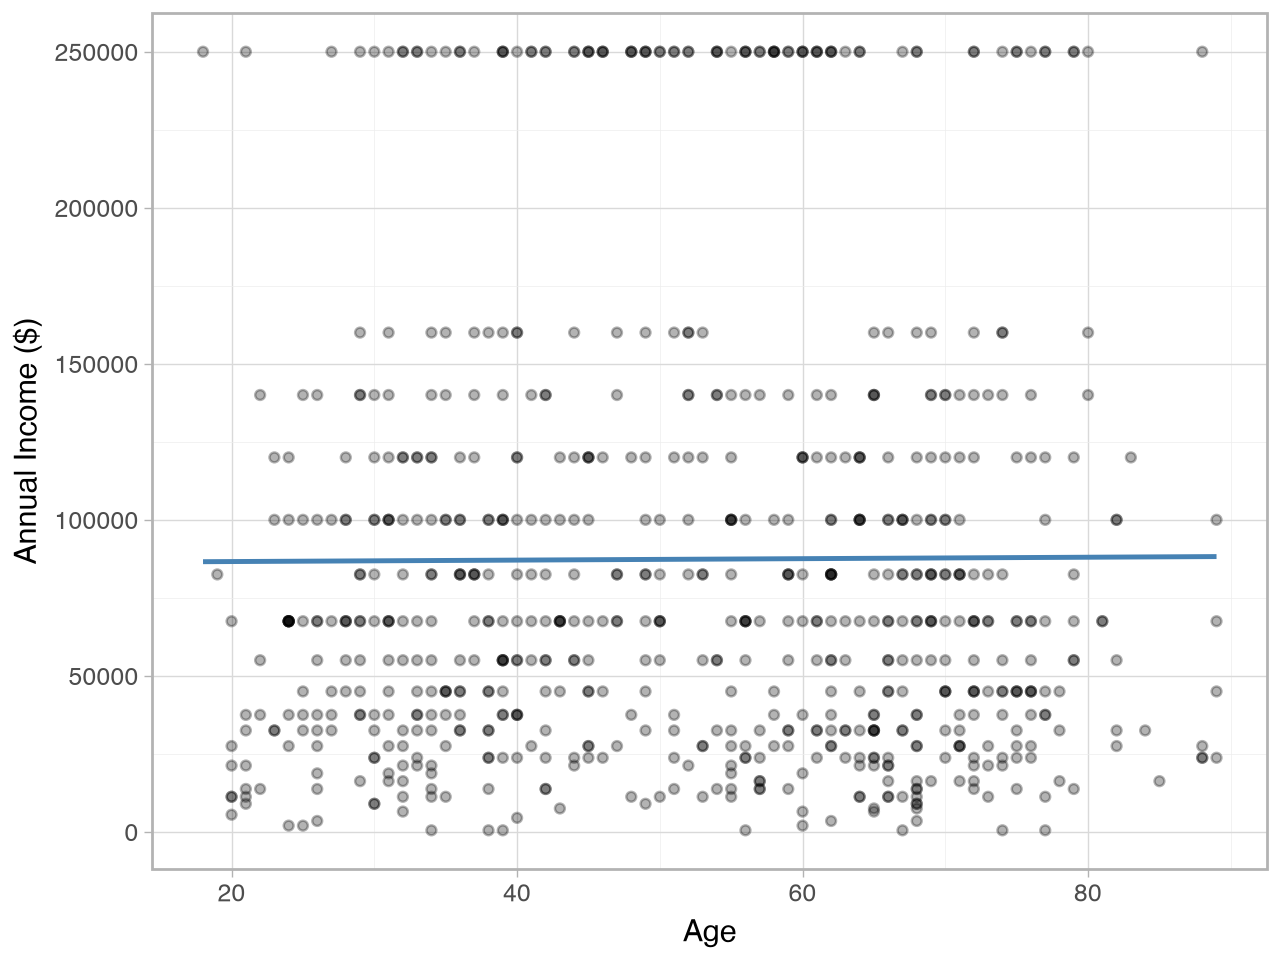

In [5]:
(
	p9.ggplot(df, p9.aes(x='age', y='income_cont')) +
	p9.geom_point(alpha=0.3) +
	p9.geom_smooth(method='lm', se=False, color='steelblue') + # adds a best fit line to the graph. se=False tells python not to add the shaded confidence interval to the graph
	p9.theme_light() +
	p9.labs(x='Age', y='Annual Income ($)')
)

## Bivariate statistic

Pearson correlation — appropriate for two continuous variables. Comment on the magnitude, direction, and p-value.

In [6]:
r, p = stats.pearsonr(df['age'], df['income_cont'])
print(f'Pearson r = {r:.4f}, p-value = {p:.4f}')
# Since r is very close to zero and positive, there is a very weak positive linear correlation between age and income
# since p-value=0.8822 > 0.05, there is insufficient evidence that age has an effect on income.

Pearson r = 0.0056, p-value = 0.8822


# Investigating income and cultural omnivorousness

## Data Visualisation

Omnivorousness is ordinal (0–4), so a boxplot is appropriate.

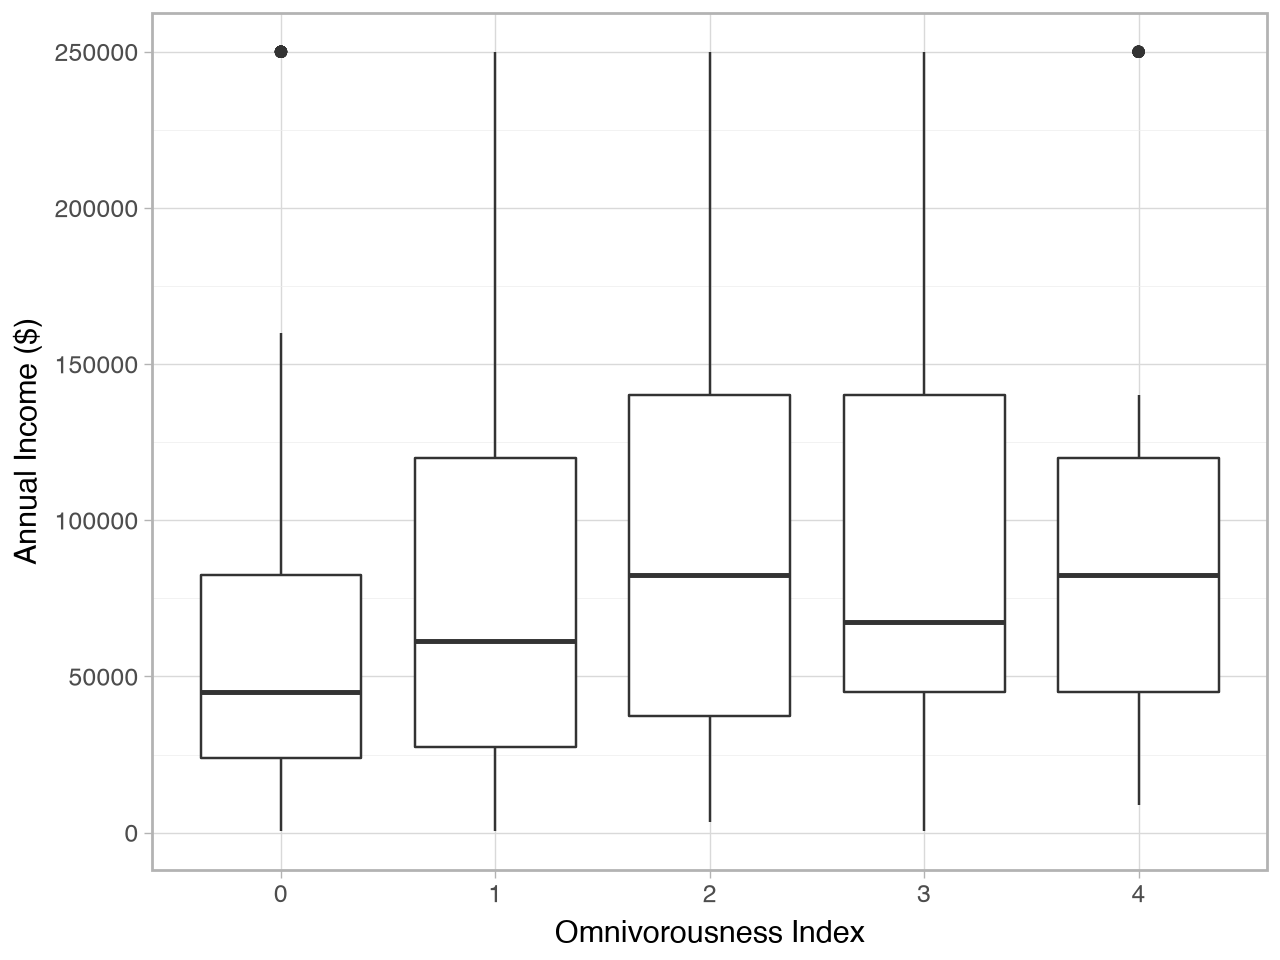

In [7]:
(
	p9.ggplot(df, p9.aes(x='factor(omni)', y='income_cont')) +
	p9.geom_boxplot() +
	p9.theme_light() +
	p9.labs(x='Omnivorousness Index', y='Annual Income ($)')
)

## Bivariate statistic

Spearman correlation — appropriate when one variable is ordinal.

In [8]:
rho, p = stats.spearmanr(df['omni'], df['income_cont'])
print(f'Spearman rho = {rho:.4f}, p-value = {p:.4f}')
# since rho = 0.2072, there is a weak monotonically increasing relationship. As omnivoureness index increases, income tends to increase slightly, but this relationship is weak
# Since p-value = 0, there is sufficient evidence that omnivoureness index affects one's income.

Spearman rho = 0.2072, p-value = 0.0000


# Investigating race and highest education level attained

## Recoding variables

In [10]:
df['race_recoded']   = df['race'].map({1: 'White', 2: 'Black'}).fillna('Other') # turn 3 = other values and NA values into 'Other'
df['degree_recoded'] = df['degree'].map({
	0: '1:<HS', 1: '2:HS', 2: '3:Assoc.', 3: '4:BA', 4: '5:Grad.'
}) # HS stands for high school

## Preliminary visualisation

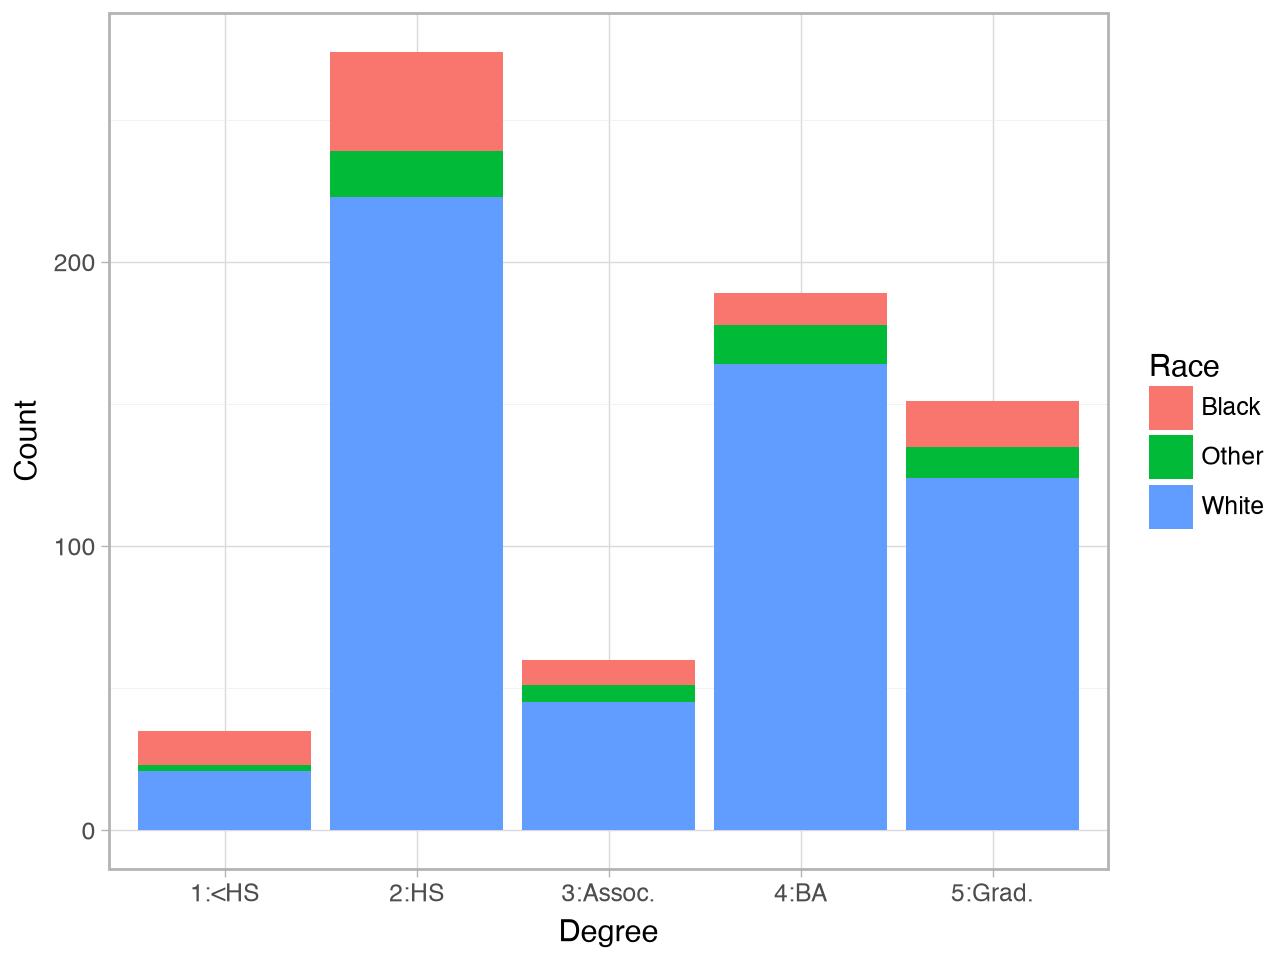

In [11]:
(
	p9.ggplot(df) +
	p9.geom_bar(p9.aes(x='degree_recoded', fill='race_recoded')) +
	p9.theme_light() +
	p9.labs(x='Degree', y='Count', fill='Race')
)

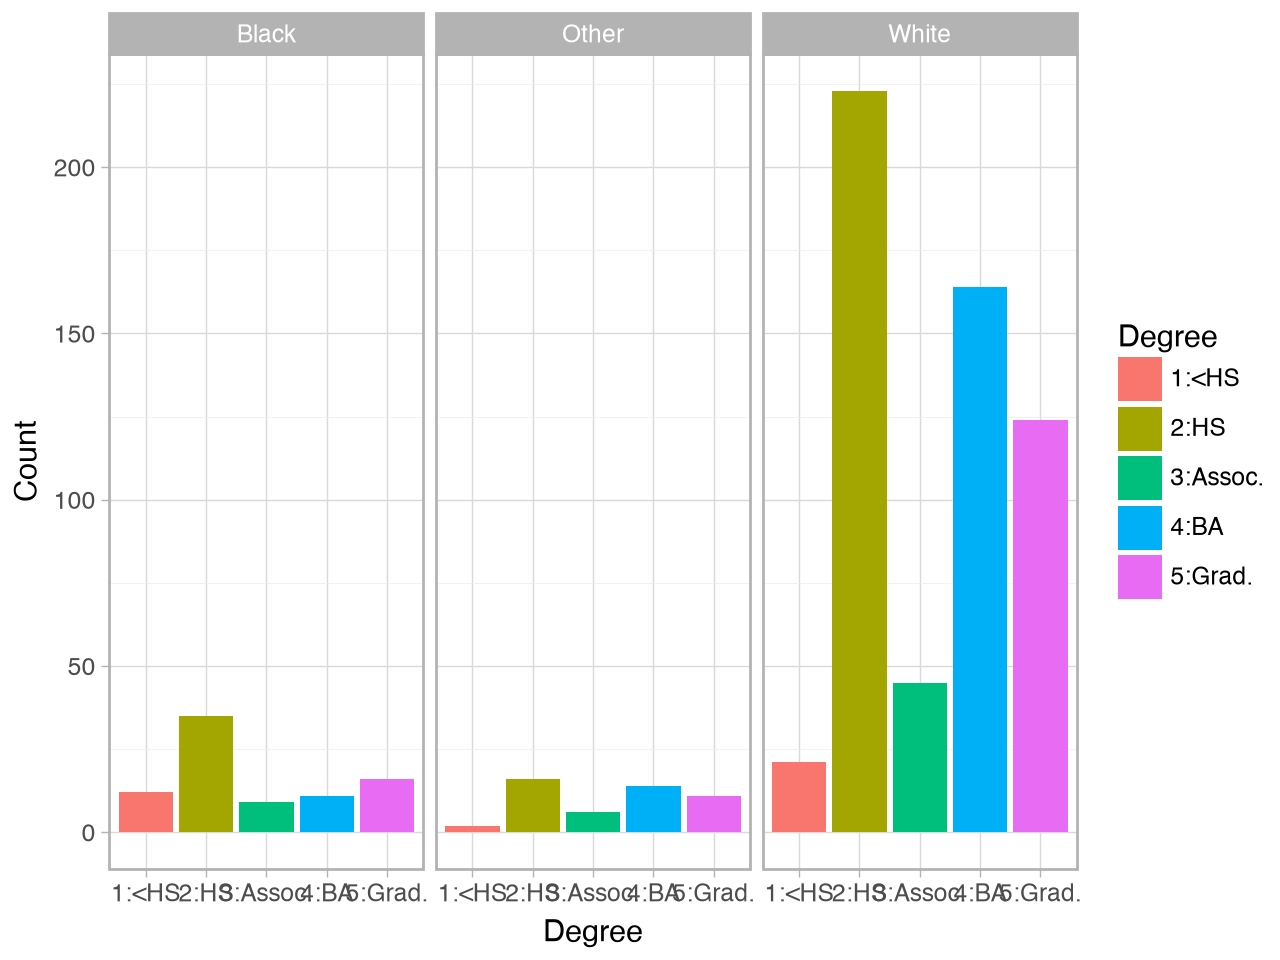

In [12]:
(
	p9.ggplot(df) +
	p9.geom_bar(p9.aes(x='degree_recoded', fill='degree_recoded')) +
	p9.facet_wrap('race_recoded') +
	p9.theme_light() +
	p9.labs(x='Degree', y='Count', fill='Degree') # easier to see relationship between race and education like this
)

## Bivariate statistic: Chi-square and Cramér's V

Chi-square tests if there is a statistically significant association. Cramér's V measures the strength of that association (0 = no association, 1 = perfect).

In [13]:
# create a table of race by education. need to do this in order to have chi-squared test
contingency = pd.crosstab(df['race_recoded'], df['degree_recoded'])

# conduct a chi squared test to determine if there is association between 2 categorical variables
# chi2_contingency conducts chi-squared test
chi2_result = stats.chi2_contingency(contingency)
cramerv_result = stats.contingency.association(contingency, method='cramer')
# chi-squared statistic is 23.223, p-value is 0.000961, degrees of freedom = 8
# expected frequency array shows the values we would expect to see in the table above if race and education were truly independent (i.e. no association)
# Since p-value < 0.05, there is sufficient evidence to reject the null hypothesis. race and education ar related

In [14]:
# association calculates degree of assocation between 2 nominal variables. method chosen is cramer's V
cramerv_result = stats.contingency.association(contingency, method='cramer')
print(f"Cramer's V = {cramerv_result:.4f}")
# since cramer's V = 0.1360, there is a weak association between race and education

Cramer's V = 0.1360


In [15]:
!jupyter nbconvert --to pdf week4_notebook_student.ipynb

[NbConvertApp] Converting notebook week4_notebook_student.ipynb to pdf
/Users/yu/Documents/hs4002_ay26/hs4002_labs2026/.venv/lib/python3.12/site-packages/nbformat/validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
[NbConvertApp] Writing 37273 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 44338 bytes to week4_notebook_student.pdf
